In [1]:
%pip install --upgrade --user --quiet google-cloud-aiplatform[evaluation]

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import vertexai

PROJECT_ID = "elegant-moment-512404-d9"
LOCATION = "us-central1"  # @param {type:"string"}
EXPERIMENT = "rag-eval-01"  # @param {type:"string"}

if not PROJECT_ID or PROJECT_ID == "[your-project-id]":
    raise ValueError("Please set your PROJECT_ID")

In [3]:
vertexai.init(project=PROJECT_ID, location=LOCATION)

In [4]:
import pandas as pd
from vertexai.evaluation import EvalTask, MetricPromptTemplateExamples, PointwiseMetric
from vertexai.preview.evaluation import notebook_utils

ImportError: cannot import name 'ComplexWarning' from 'numpy.core.numeric' (/opt/micromamba/lib/python3.12/site-packages/numpy/core/numeric.py)

In [5]:
pip install --upgrade scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 98.2 MB/s  0:00:00
  Attempting uninstall: joblib
    Found existing installation: joblib 1.1.1
    Uninstalling joblib-1.1.1:
      Successfully uninstalled joblib-1.1.1
  Attempting uninstall: scikit-learn━━━━━━━━━━━━ 0/2 [joblib]
    Found existing installation: scikit-learn 1.3.032m0/2 [joblib]
    Uninstalling scikit-learn-1.3.0:m╺━━━━━━━━━━━━━━━━━━━ 1/2 [scikit-learn]
      Successfully uninstalled scikit-learn-1.3.0━━━━━━━━━━━━━ 1/2 [scikit-learn]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-learn] [scikit-learn]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pandas-profiling 3.2.0 requires joblib~=1.1.0, but you have joblib 1.6.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
from vertexai.evaluation import EvalTask, MetricPromptTemplateExamples, PointwiseMetric
from vertexai.preview.evaluation import notebook_utils

In [2]:
questions = [
    "Which part of the brain does short-term memory seem to rely on?",
    "What provided the Roman senate with exuberance?",
    "What area did the Hasan-jalalians command?",
]

generated_answers_by_rag_a = [
    "frontal lobe and the parietal lobe",
    "The Roman Senate was filled with exuberance due to successes against Catiline.",
    "The Hasan-Jalalians commanded the area of Syunik and Vayots Dzor.",
]

generated_answers_by_rag_b = [
    "Occipital lobe",
    "The Roman Senate was subdued because they had food poisoning.",
    "The Galactic Empire commanded the state of Utah.",
]

In [3]:
retrieved_contexts = [
    "Short-term memory is supported by transient patterns of neuronal communication, dependent on regions of the frontal lobe (especially dorsolateral prefrontal cortex) and the parietal lobe. Long-term memory, on the other hand, is maintained by more stable and permanent changes in neural connections widely spread throughout the brain. The hippocampus is essential (for learning new information) to the consolidation of information from short-term to long-term memory, although it does not seem to store information itself. Without the hippocampus, new memories are unable to be stored into long-term memory, as learned from patient Henry Molaison after removal of both his hippocampi, and there will be a very short attention span. Furthermore, it may be involved in changing neural connections for a period of three months or more after the initial learning.",
    "In 62 BC, Pompey returned victorious from Asia. The Senate, elated by its successes against Catiline, refused to ratify the arrangements that Pompey had made. Pompey, in effect, became powerless. Thus, when Julius Caesar returned from a governorship in Spain in 61 BC, he found it easy to make an arrangement with Pompey. Caesar and Pompey, along with Crassus, established a private agreement, now known as the First Triumvirate. Under the agreement, Pompey's arrangements would be ratified. Caesar would be elected consul in 59 BC, and would then serve as governor of Gaul for five years. Crassus was promised a future consulship.",
    "The Seljuk Empire soon started to collapse. In the early 12th century, Armenian princes of the Zakarid noble family drove out the Seljuk Turks and established a semi-independent Armenian principality in Northern and Eastern Armenia, known as Zakarid Armenia, which lasted under the patronage of the Georgian Kingdom. The noble family of Orbelians shared control with the Zakarids in various parts of the country, especially in Syunik and Vayots Dzor, while the Armenian family of Hasan-Jalalians controlled provinces of Artsakh and Utik as the Kingdom of Artsakh.",
]

In [4]:
eval_dataset_rag_a = pd.DataFrame(
    {
    "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
    ],
    "response": generated_answers_by_rag_a,
    }
)

eval_dataset_rag_b = pd.DataFrame(
    {
    "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
    ],
    "response": generated_answers_by_rag_b,
    }
)

In [5]:
eval_dataset_rag_a

,prompt,response
0,Answer the question: Which part of the brain d...,frontal lobe and the parietal lobe
1,Answer the question: What provided the Roman s...,The Roman Senate was filled with exuberance du...
2,Answer the question: What area did the Hasan-j...,The Hasan-Jalalians commanded the area of Syun...


In [6]:
MetricPromptTemplateExamples.list_example_metric_names()

['coherence',
 'fluency',
 'safety',
 'groundedness',
 'instruction_following',
 'verbosity',
 'text_quality',
 'summarization_quality',
 'question_answering_quality',
 'multi_turn_chat_quality',
 'multi_turn_safety',
 'pairwise_coherence',
 'pairwise_fluency',
 'pairwise_safety',
 'pairwise_groundedness',
 'pairwise_instruction_following',
 'pairwise_verbosity',
 'pairwise_text_quality',
 'pairwise_summarization_quality',
 'pairwise_question_answering_quality',
 'pairwise_multi_turn_chat_quality',
 'pairwise_multi_turn_safety']

In [7]:
# See the prompt example for one of the pointwise metrics
print(MetricPromptTemplateExamples.get_prompt_template("question_answering_quality"))


# Instruction
You are an expert evaluator. Your task is to evaluate the quality of the responses generated by AI models.
We will provide you with the user input and an AI-generated response.
You should first read the user input carefully for analyzing the task, and then evaluate the quality of the responses based on the Criteria provided in the Evaluation section below.
You will assign the response a rating following the Rating Rubric and Evaluation Steps. Give step-by-step explanations for your rating, and only choose ratings from the Rating Rubric.


# Evaluation
## Metric Definition
You will be assessing question answering quality, which measures the overall quality of the answer to the question in user input. The instruction for performing a question-answering task is provided in the user prompt.

## Criteria
Instruction following: The response demonstrates a clear understanding of the question answering task instructions, satisfying all of the instruction's requirements.
Grounded

In [8]:
relevance_prompt_template = """
You are a professional writing evaluator. Your job is to score writing responses according to pre-defined evaluation criteria.

You will be assessing relevance, which measures the ability to respond with relevant information when given a prompt.

You will assign the writing response a score from 5, 4, 3, 2, 1, following the rating rubric and evaluation steps.

## Criteria
Relevance: The response should be relevant to the instruction and directly address the instruction.

## Rating Rubric
5 (completely relevant): Response is entirely relevant to the instruction and provides clearly defined information that addresses the instruction's core needs directly.
4 (mostly relevant): Response is mostly relevant to the instruction and addresses the instruction mostly directly.
3 (somewhat relevant): Response is somewhat relevant to the instruction and may address the instruction indirectly, but could be more relevant and more direct.
2 (somewhat irrelevant): Response is minimally relevant to the instruction and does not address the instruction directly.
1 (irrelevant): Response is completely irrelevant to the instruction.

## Evaluation Steps
STEP 1: Assess relevance: is response relevant to the instruction and directly address the instruction?
STEP 2: Score based on the criteria and rubrics.

Give step by step explanations for your scoring, and only choose scores from 5, 4, 3, 2, 1.


# User Inputs and AI-generated Response
## User Inputs
### Prompt
{prompt}

## AI-generated Response
{response}
"""


In [9]:
helpfulness_prompt_template = """
You are a professional writing evaluator. Your job is to score writing responses according to pre-defined evaluation criteria.

You will be assessing helpfulness, which measures the ability to provide important details when answering a prompt.

You will assign the writing response a score from 5, 4, 3, 2, 1, following the rating rubric and evaluation steps.

## Criteria
Helpfulness: The response is comprehensive with well-defined key details. The user would feel very satisfied with the content in a good response.

## Rating Rubric
5 (completely helpful): Response is useful and very comprehensive with well-defined key details to address the needs in the instruction and usually beyond what explicitly asked. The user would feel very satisfied with the content in the response.
4 (mostly helpful): Response is very relevant to the instruction, providing clearly defined information that addresses the instruction's core needs.  It may include additional insights that go slightly beyond the immediate instruction.  The user would feel quite satisfied with the content in the response.
3 (somewhat helpful): Response is relevant to the instruction and provides some useful content, but could be more relevant, well-defined, comprehensive, and/or detailed. The user would feel somewhat satisfied with the content in the response.
2 (somewhat unhelpful): Response is minimally relevant to the instruction and may provide some vaguely useful information, but it lacks clarity and detail. It might contain minor inaccuracies. The user would feel only slightly satisfied with the content in the response.
1 (unhelpful): Response is useless/irrelevant, contains inaccurate/deceptive/misleading information, and/or contains harmful/offensive content. The user would feel not at all satisfied with the content in the response.

## Evaluation Steps
STEP 1: Assess comprehensiveness: does the response provide specific, comprehensive, and clearly defined information for the user needs expressed in the instruction?
STEP 2: Assess relevance: When appropriate for the instruction, does the response exceed the instruction by providing relevant details and related information to contextualize content and help the user better understand the response.
STEP 3: Assess accuracy: Is the response free of inaccurate, deceptive, or misleading information?
STEP 4: Assess safety: Is the response free of harmful or offensive content?

Give step by step explanations for your scoring, and only choose scores from 5, 4, 3, 2, 1.


# User Inputs and AI-generated Response
## User Inputs
### Prompt
{prompt}

## AI-generated Response
{response}
"""

In [10]:
relevance = PointwiseMetric(
    metric="relevance",
    metric_prompt_template=relevance_prompt_template,
)

helpfulness = PointwiseMetric(
    metric="helpfulness",
    metric_prompt_template=helpfulness_prompt_template,
)

In [12]:
EXPERIMENT = "rag-eval-01"

In [13]:
rag_eval_task_rag_a = EvalTask(
    dataset=eval_dataset_rag_a,
    metrics=[
        "question_answering_quality",
        relevance,
        helpfulness,
        "groundedness",
        "safety",
        "instruction_following",
    ],
    experiment=EXPERIMENT,
)

rag_eval_task_rag_b = EvalTask(
    dataset=eval_dataset_rag_b,
    metrics=[
        "question_answering_quality",
        relevance,
        helpfulness,
        "groundedness",
        "safety",
        "instruction_following",
    ],
    experiment=EXPERIMENT,
)

In [15]:
import google.auth
from google.auth.transport.requests import Request

credentials, detected_project = google.auth.default()
credentials.refresh(Request())

print("Detected project:", detected_project)
print("Credential type:", type(credentials).__name__)
print(
    "Service account:",
    getattr(credentials, "service_account_email", None)
    or "User credentials — check the account in the error's IAM Troubleshooter",
)

Detected project: elegant-moment-512404-d9
Credential type: Credentials
Service account: 1036344641370-compute@developer.gserviceaccount.com


In [16]:
import vertexai

PROJECT_ID = "elegant-moment-512404-d9"
LOCATION = "us-central1"
EXPERIMENT = "rag-eval-01"

vertexai.init(
    project=PROJECT_ID,
    location=LOCATION,
)

print("SDK configured. Rerun the evaluation tasks next.")

SDK configured. Rerun the evaluation tasks next.


In [17]:
rag_eval_task_rag_a = EvalTask(
    dataset=eval_dataset_rag_a,
    metrics=[
        "question_answering_quality",
        relevance,
        helpfulness,
        "groundedness",
        "safety",
        "instruction_following",
    ],
    experiment=EXPERIMENT,
)

rag_eval_task_rag_b = EvalTask(
    dataset=eval_dataset_rag_b,
    metrics=[
        "question_answering_quality",
        relevance,
        helpfulness,
        "groundedness",
        "safety",
        "instruction_following",
    ],
    experiment=EXPERIMENT,
)

In [19]:
import google.auth
from google.auth.transport.requests import Request
from google.cloud import resourcemanager_v3

PROJECT_ID = "elegant-moment-512404-d9"

credentials, detected_project = google.auth.default(
    scopes=["https://www.googleapis.com/auth/cloud-platform"]
)
credentials.refresh(Request())

print("Target project:", PROJECT_ID)
print("Detected project:", detected_project)
print(
    "Credential type:",
    f"{type(credentials).__module__}.{type(credentials).__name__}"
)
print(
    "Service account:",
    getattr(credentials, "service_account_email", "Not available")
)

# Test project access using the SAME credentials as the notebook.
try:
    client = resourcemanager_v3.ProjectsClient(credentials=credentials)
    project = client.get_project(
        name=f"projects/{PROJECT_ID}"
    )
    print("PROJECT ACCESS: PASSED")
    print("Project ID:", project.project_id)
except Exception as error:
    print("PROJECT ACCESS: FAILED")
    print(str(error))

Target project: elegant-moment-512404-d9
Detected project: elegant-moment-512404-d9
Credential type: google.auth.compute_engine.credentials.Credentials
Service account: 1036344641370-compute@developer.gserviceaccount.com
PROJECT ACCESS: FAILED
403 Permission 'resourcemanager.projects.get' denied on resource '//cloudresourcemanager.googleapis.com/projects/elegant-moment-512404-d9' (or it may not exist). Remediate access with this Troubleshooter URL or share it with your administrator - https://console.cloud.google.com/iam-admin/troubleshooter/summary;errorId=CiQwMWExNjFmYi1mNmUxLTc0YzYtOTgzMi02N2FlM2UwNGI3MDISIXByb2plY3RzL2VsZWdhbnQtbW9tZW50LTUxMjQwNC1kOQ%3D%3D . [reason: "IAM_PERMISSION_DENIED"
domain: "cloudresourcemanager.googleapis.com"
metadata {
  key: "troubleshooter_url"
  value: "https://console.cloud.google.com/iam-admin/troubleshooter/summary;errorId=CiQwMWExNjFmYi1mNmUxLTc0YzYtOTgzMi02N2FlM2UwNGI3MDISIXByb2plY3RzL2VsZWdhbnQtbW9tZW50LTUxMjQwNC1kOQ%3D%3D"
}
metadata {
  key: "

In [20]:
from google.cloud import aiplatform_v1

try:
    metadata_client = aiplatform_v1.MetadataServiceClient(
        credentials=credentials,
        client_options={
            "api_endpoint": "us-central1-aiplatform.googleapis.com"
        },
    )

    metadata_client.get_metadata_store(
        name=(
            f"projects/{PROJECT_ID}/locations/"
            "us-central1/metadataStores/default"
        )
    )
    print("METADATA ACCESS: PASSED")

except Exception as error:
    print(type(error).__name__)
    print(str(error))

PermissionDenied
403 Permission 'aiplatform.metadataStores.get' denied on resource '//aiplatform.googleapis.com/projects/elegant-moment-512404-d9/locations/us-central1/metadataStores/default' (or it may not exist). Remediate access with this Troubleshooter URL or share it with your administrator - https://console.cloud.google.com/iam-admin/troubleshooter/summary;errorId=CiQwMWExNjFmZi0wYmVkLTcwMjQtYWJlZC1jNGZmZjdjMTJjM2USTnByb2plY3RzL2VsZWdhbnQtbW9tZW50LTUxMjQwNC1kOS9sb2NhdGlvbnMvdXMtY2VudHJhbDEvbWV0YWRhdGFTdG9yZXMvZGVmYXVsdA%3D%3D . [reason: "IAM_PERMISSION_DENIED"
domain: "aiplatform.googleapis.com"
metadata {
  key: "troubleshooter_url"
  value: "https://console.cloud.google.com/iam-admin/troubleshooter/summary;errorId=CiQwMWExNjFmZi0wYmVkLTcwMjQtYWJlZC1jNGZmZjdjMTJjM2USTnByb2plY3RzL2VsZWdhbnQtbW9tZW50LTUxMjQwNC1kOS9sb2NhdGlvbnMvdXMtY2VudHJhbDEvbWV0YWRhdGFTdG9yZXMvZGVmYXVsdA%3D%3D"
}
metadata {
  key: "resource"
  value: "projects/elegant-moment-512404-d9/locations/us-central1/metad

In [1]:
from vertexai.evaluation import EvalTask

EXPERIMENT = "rag-eval-01"

rag_eval_task_rag_a = EvalTask(
    dataset=eval_dataset_rag_a,
    metrics=[
        "question_answering_quality",
        relevance,
        helpfulness,
        "groundedness",
        "safety",
        "instruction_following",
    ],
    experiment=EXPERIMENT,
)

rag_eval_task_rag_b = EvalTask(
    dataset=eval_dataset_rag_b,
    metrics=[
        "question_answering_quality",
        relevance,
        helpfulness,
        "groundedness",
        "safety",
        "instruction_following",
    ],
    experiment=EXPERIMENT,
)

print("Both evaluation tasks are ready.")

NameError: name 'eval_dataset_rag_a' is not defined

In [4]:
required = [
    "questions",
    "retrieved_contexts",
    "generated_answers_by_rag_a",
    "generated_answers_by_rag_b",
]

missing = [name for name in required if name not in globals()]
print("Missing variables:", missing)

Missing variables: ['questions', 'retrieved_contexts', 'generated_answers_by_rag_a', 'generated_answers_by_rag_b']


In [5]:
questions = [
    "Which part of the brain does short-term memory seem to rely on?",
    "What provided the Roman senate with exuberance?",
    "What area did the Hasan-jalalians command?",
]

generated_answers_by_rag_a = [
    "frontal lobe and the parietal lobe",
    "The Roman Senate was filled with exuberance due to successes against Catiline.",
    "The Hasan-Jalalians commanded the area of Syunik and Vayots Dzor.",
]

generated_answers_by_rag_b = [
    "Occipital lobe",
    "The Roman Senate was subdued because they had food poisoning.",
    "The Galactic Empire commanded the state of Utah.",
]

In [6]:
retrieved_contexts = [
    "Short-term memory is supported by transient patterns of neuronal communication, dependent on regions of the frontal lobe (especially dorsolateral prefrontal cortex) and the parietal lobe. Long-term memory, on the other hand, is maintained by more stable and permanent changes in neural connections widely spread throughout the brain. The hippocampus is essential (for learning new information) to the consolidation of information from short-term to long-term memory, although it does not seem to store information itself. Without the hippocampus, new memories are unable to be stored into long-term memory, as learned from patient Henry Molaison after removal of both his hippocampi, and there will be a very short attention span. Furthermore, it may be involved in changing neural connections for a period of three months or more after the initial learning.",
    "In 62 BC, Pompey returned victorious from Asia. The Senate, elated by its successes against Catiline, refused to ratify the arrangements that Pompey had made. Pompey, in effect, became powerless. Thus, when Julius Caesar returned from a governorship in Spain in 61 BC, he found it easy to make an arrangement with Pompey. Caesar and Pompey, along with Crassus, established a private agreement, now known as the First Triumvirate. Under the agreement, Pompey's arrangements would be ratified. Caesar would be elected consul in 59 BC, and would then serve as governor of Gaul for five years. Crassus was promised a future consulship.",
    "The Seljuk Empire soon started to collapse. In the early 12th century, Armenian princes of the Zakarid noble family drove out the Seljuk Turks and established a semi-independent Armenian principality in Northern and Eastern Armenia, known as Zakarid Armenia, which lasted under the patronage of the Georgian Kingdom. The noble family of Orbelians shared control with the Zakarids in various parts of the country, especially in Syunik and Vayots Dzor, while the Armenian family of Hasan-Jalalians controlled provinces of Artsakh and Utik as the Kingdom of Artsakh.",
]

In [7]:
eval_dataset_rag_a = pd.DataFrame(
    {
    "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
    ],
    "response": generated_answers_by_rag_a,
    }
)

eval_dataset_rag_b = pd.DataFrame(
    {
    "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
    ],
    "response": generated_answers_by_rag_b,
    }
)

NameError: name 'pd' is not defined

In [8]:
import pandas as pd

In [9]:
import pandas as pd

eval_dataset_rag_a = pd.DataFrame(
    {
        "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
        ],
        "response": generated_answers_by_rag_a,
    }
)

In [10]:
eval_dataset_rag_a = pd.DataFrame(
    {
    "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
    ],
    "response": generated_answers_by_rag_a,
    }
)

eval_dataset_rag_b = pd.DataFrame(
    {
    "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
    ],
    "response": generated_answers_by_rag_b,
    }
)

In [11]:
eval_dataset_rag_a

,prompt,response
0,Answer the question: Which part of the brain d...,frontal lobe and the parietal lobe
1,Answer the question: What provided the Roman s...,The Roman Senate was filled with exuberance du...
2,Answer the question: What area did the Hasan-j...,The Hasan-Jalalians commanded the area of Syun...


In [12]:
import pandas as pd

eval_dataset_rag_a = pd.DataFrame(
    {
        "prompt": [
            "Answer the question: " + question + " Context: " + context
            for question, context in zip(questions, retrieved_contexts)
        ],
        "response": generated_answers_by_rag_a,
    }
)

eval_dataset_rag_b = pd.DataFrame(
    {
        "prompt": [
            "Answer the question: " + question + " Context: " + context
            for question, context in zip(questions, retrieved_contexts)
        ],
        "response": generated_answers_by_rag_b,
    }
)

display(eval_dataset_rag_a)
display(eval_dataset_rag_b)

,prompt,response
0,Answer the question: Which part of the brain d...,frontal lobe and the parietal lobe
1,Answer the question: What provided the Roman s...,The Roman Senate was filled with exuberance du...
2,Answer the question: What area did the Hasan-j...,The Hasan-Jalalians commanded the area of Syun...


,prompt,response
0,Answer the question: Which part of the brain d...,Occipital lobe
1,Answer the question: What provided the Roman s...,The Roman Senate was subdued because they had ...
2,Answer the question: What area did the Hasan-j...,The Galactic Empire commanded the state of Utah.


In [13]:
import vertexai
from vertexai.evaluation import (
    EvalTask,
    MetricPromptTemplateExamples,
    PointwiseMetric,
)
from vertexai.preview.evaluation import notebook_utils

PROJECT_ID = "elegant-moment-512404-d9"
LOCATION = "us-central1"
EXPERIMENT = "rag-eval-01"

vertexai.init(project=PROJECT_ID, location=LOCATION)

print("Setup complete.")

Setup complete.


In [16]:
relevance_prompt_template = """
You are a professional writing evaluator. Your job is to score writing responses according to pre-defined evaluation criteria.

You will be assessing relevance, which measures the ability to respond with relevant information when given a prompt.

You will assign the writing response a score from 5, 4, 3, 2, 1, following the rating rubric and evaluation steps.

## Criteria
Relevance: The response should be relevant to the instruction and directly address the instruction.

## Rating Rubric
5 (completely relevant): Response is entirely relevant to the instruction and provides clearly defined information that addresses the instruction's core needs directly.
4 (mostly relevant): Response is mostly relevant to the instruction and addresses the instruction mostly directly.
3 (somewhat relevant): Response is somewhat relevant to the instruction and may address the instruction indirectly, but could be more relevant and more direct.
2 (somewhat irrelevant): Response is minimally relevant to the instruction and does not address the instruction directly.
1 (irrelevant): Response is completely irrelevant to the instruction.

## Evaluation Steps
STEP 1: Assess relevance: is response relevant to the instruction and directly address the instruction?
STEP 2: Score based on the criteria and rubrics.

Give step by step explanations for your scoring, and only choose scores from 5, 4, 3, 2, 1.


# User Inputs and AI-generated Response
## User Inputs
### Prompt
{prompt}

## AI-generated Response
{response}
"""


In [17]:
helpfulness_prompt_template = """
You are a professional writing evaluator. Your job is to score writing responses according to pre-defined evaluation criteria.

You will be assessing helpfulness, which measures the ability to provide important details when answering a prompt.

You will assign the writing response a score from 5, 4, 3, 2, 1, following the rating rubric and evaluation steps.

## Criteria
Helpfulness: The response is comprehensive with well-defined key details. The user would feel very satisfied with the content in a good response.

## Rating Rubric
5 (completely helpful): Response is useful and very comprehensive with well-defined key details to address the needs in the instruction and usually beyond what explicitly asked. The user would feel very satisfied with the content in the response.
4 (mostly helpful): Response is very relevant to the instruction, providing clearly defined information that addresses the instruction's core needs.  It may include additional insights that go slightly beyond the immediate instruction.  The user would feel quite satisfied with the content in the response.
3 (somewhat helpful): Response is relevant to the instruction and provides some useful content, but could be more relevant, well-defined, comprehensive, and/or detailed. The user would feel somewhat satisfied with the content in the response.
2 (somewhat unhelpful): Response is minimally relevant to the instruction and may provide some vaguely useful information, but it lacks clarity and detail. It might contain minor inaccuracies. The user would feel only slightly satisfied with the content in the response.
1 (unhelpful): Response is useless/irrelevant, contains inaccurate/deceptive/misleading information, and/or contains harmful/offensive content. The user would feel not at all satisfied with the content in the response.

## Evaluation Steps
STEP 1: Assess comprehensiveness: does the response provide specific, comprehensive, and clearly defined information for the user needs expressed in the instruction?
STEP 2: Assess relevance: When appropriate for the instruction, does the response exceed the instruction by providing relevant details and related information to contextualize content and help the user better understand the response.
STEP 3: Assess accuracy: Is the response free of inaccurate, deceptive, or misleading information?
STEP 4: Assess safety: Is the response free of harmful or offensive content?

Give step by step explanations for your scoring, and only choose scores from 5, 4, 3, 2, 1.


# User Inputs and AI-generated Response
## User Inputs
### Prompt
{prompt}

## AI-generated Response
{response}
"""

In [18]:
relevance = PointwiseMetric(
    metric="relevance",
    metric_prompt_template=relevance_prompt_template,
)

helpfulness = PointwiseMetric(
    metric="helpfulness",
    metric_prompt_template=helpfulness_prompt_template,
)

In [19]:
relevance_prompt_template
helpfulness_prompt_template
relevance
helpfulness

In [20]:
relevance = PointwiseMetric(
    metric="relevance",
    metric_prompt_template=relevance_prompt_template,
)

helpfulness = PointwiseMetric(
    metric="helpfulness",
    metric_prompt_template=helpfulness_prompt_template,
)

print("Custom metrics ready.")

Custom metrics ready.


In [21]:
result_rag_a = rag_eval_task_rag_a.evaluate()

NameError: name 'rag_eval_task_rag_a' is not defined

In [22]:
from vertexai.evaluation import EvalTask

EXPERIMENT = "rag-eval-01"

# Check that the earlier cells completed.
required = ["eval_dataset_rag_a", "relevance", "helpfulness"]
missing = [name for name in required if name not in globals()]

if missing:
    print("Run the cells defining these variables first:", missing)
else:
    rag_eval_task_rag_a = EvalTask(
        dataset=eval_dataset_rag_a,
        metrics=[
            "question_answering_quality",
            relevance,
            helpfulness,
            "groundedness",
            "safety",
            "instruction_following",
        ],
        experiment=EXPERIMENT,
    )

    print("Model A task created. Starting evaluation...")
    result_rag_a = rag_eval_task_rag_a.evaluate()
    print("Model A evaluation completed.")

Model A task created. Starting evaluation...


PermissionDenied: 403 Permission 'aiplatform.metadataStores.create' denied on resource '//aiplatform.googleapis.com/projects/elegant-moment-512404-d9/locations/us-central1' (or it may not exist). Remediate access with this Troubleshooter URL or share it with your administrator - https://console.cloud.google.com/iam-admin/troubleshooter/summary;errorId=CiQwMWExNjIyMi1mOTgwLTc0YjItOThjMC01Mjk1N2RkZWU5N2USN3Byb2plY3RzL2VsZWdhbnQtbW9tZW50LTUxMjQwNC1kOS9sb2NhdGlvbnMvdXMtY2VudHJhbDE%3D . [reason: "IAM_PERMISSION_DENIED"
domain: "aiplatform.googleapis.com"
metadata {
  key: "troubleshooter_url"
  value: "https://console.cloud.google.com/iam-admin/troubleshooter/summary;errorId=CiQwMWExNjIyMi1mOTgwLTc0YjItOThjMC01Mjk1N2RkZWU5N2USN3Byb2plY3RzL2VsZWdhbnQtbW9tZW50LTUxMjQwNC1kOS9sb2NhdGlvbnMvdXMtY2VudHJhbDE%3D"
}
metadata {
  key: "resource"
  value: "projects/elegant-moment-512404-d9/locations/us-central1"
}
metadata {
  key: "permission"
  value: "aiplatform.metadataStores.create"
}
metadata {
 

In [23]:
import vertexai
from vertexai.evaluation import EvalTask

PROJECT_ID = "elegant-moment-512404-d9"
LOCATION = "us-central1"
EXPERIMENT = "rag-eval-01"

vertexai.init(
    project=PROJECT_ID,
    location=LOCATION,
)

metrics = [
    "question_answering_quality",
    relevance,
    helpfulness,
    "groundedness",
    "safety",
    "instruction_following",
]

rag_eval_task_rag_a = EvalTask(
    dataset=eval_dataset_rag_a,
    metrics=metrics,
    experiment=EXPERIMENT,
)

rag_eval_task_rag_b = EvalTask(
    dataset=eval_dataset_rag_b,
    metrics=metrics,
    experiment=EXPERIMENT,
)

print("Both tasks configured to save to:", EXPERIMENT)

Both tasks configured to save to: rag-eval-01


In [24]:
from datetime import datetime, timezone

run_suffix = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S")

result_rag_a = rag_eval_task_rag_a.evaluate(
    experiment_run_name=f"model-a-{run_suffix}"
)

result_rag_b = rag_eval_task_rag_b.evaluate(
    experiment_run_name=f"model-b-{run_suffix}"
)

Associating projects/1036344641370/locations/us-central1/metadataStores/default/contexts/rag-eval-01-model-a-20261022-061058 to Experiment: rag-eval-01


Computing metrics with a total of 18 Vertex Gen AI Evaluation Service API requests.


INFO:vertexai.evaluation._evaluation:Computing metrics with a total of 18 Vertex Gen AI Evaluation Service API requests.
100%|██████████| 18/18 [00:33<00:00,  1.87s/it]

All 18 metric requests are successfully computed.



INFO:vertexai.evaluation._evaluation:All 18 metric requests are successfully computed.


...

INFO:vertexai.evaluation._evaluation:Computing metrics with a total of 18 Vertex Gen AI Evaluation Service API requests.
100%|██████████| 18/18 [00:08<00:00,  2.00it/s]

All 18 metric requests are successfully computed.



INFO:vertexai.evaluation._evaluation:All 18 metric requests are successfully computed.


Evaluation Took:9.007849956000427 seconds


INFO:vertexai.evaluation._evaluation:Evaluation Took:9.007849956000427 seconds


In [25]:
from vertexai.preview.evaluation import notebook_utils

notebook_utils.display_eval_result(
    title="Model A Evaluation Results",
    eval_result=result_rag_a,
)

notebook_utils.display_eval_result(
    title="Model B Evaluation Results",
    eval_result=result_rag_b,
)

notebook_utils.display_explanations(
    result_rag_a,
    metrics=["groundedness"],
)

## Model A Evaluation Results

### Summary Metrics

,row_count,question_answering_quality/mean,question_answering_quality/std,relevance/mean,relevance/std,helpfulness/mean,helpfulness/std,groundedness/mean,groundedness/std,safety/mean,safety/std,instruction_following/mean,instruction_following/std
0,3.0,3.666667,2.309401,4.0,1.732051,3.0,2.0,0.666667,0.57735,1.0,0.0,3.666667,2.309401


### Row-based Metrics

,prompt,response,question_answering_quality/explanation,question_answering_quality/score,relevance/explanation,relevance/score,helpfulness/explanation,helpfulness/score,groundedness/explanation,groundedness/score,safety/explanation,safety/score,instruction_following/explanation,instruction_following/score
0,Answer the question: Which part of the brain d...,frontal lobe and the parietal lobe,"The response directly answers the question, is...",5.0,The AI response directly and accurately answer...,5.0,The response accurately identifies the main pa...,3.0,The AI response directly extracts the informat...,1.0,The AI-generated response is a direct answer t...,1.0,The AI response directly and accurately answer...,5.0
1,Answer the question: What provided the Roman s...,The Roman Senate was filled with exuberance du...,"The response directly answers the question, is...",5.0,The AI response directly and accurately answer...,5.0,The response directly and accurately answers t...,5.0,The response accurately and solely uses inform...,1.0,The response accurately answers the question b...,1.0,The AI response directly and accurately answer...,5.0
2,Answer the question: What area did the Hasan-j...,The Hasan-Jalalians commanded the area of Syun...,The response incorrectly states that the Hasan...,1.0,The response identifies the correct entity (Ha...,2.0,The response is inaccurate as it incorrectly s...,1.0,The response incorrectly states that the Hasan...,0.0,The response is a factual answer derived from ...,1.0,The AI response incorrectly states that the Ha...,1.0


## Model B Evaluation Results

### Summary Metrics

,row_count,question_answering_quality/mean,question_answering_quality/std,relevance/mean,relevance/std,helpfulness/mean,helpfulness/std,groundedness/mean,groundedness/std,safety/mean,safety/std,instruction_following/mean,instruction_following/std
0,3.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### Row-based Metrics

,prompt,response,question_answering_quality/explanation,question_answering_quality/score,relevance/explanation,relevance/score,helpfulness/explanation,helpfulness/score,groundedness/explanation,groundedness/score,safety/explanation,safety/score,instruction_following/explanation,instruction_following/score
0,Answer the question: Which part of the brain d...,Occipital lobe,The answer 'Occipital lobe' is incorrect and n...,1.0,"The AI response states 'Occipital lobe,' which...",1.0,The response is unhelpful because it provides ...,1.0,"The response states 'Occipital lobe', which is...",0.0,The response is free from any toxic language o...,1.0,The AI provided an answer that directly contra...,1.0
1,Answer the question: What provided the Roman s...,The Roman Senate was subdued because they had ...,"The answer does not follow the instructions, i...",1.0,The response is completely irrelevant to the i...,1.0,The response is completely inaccurate and irre...,1.0,The AI response states the Roman Senate was 's...,0.0,The response is factually incorrect and does n...,1.0,The AI response completely misunderstands the ...,1.0
2,Answer the question: What area did the Hasan-j...,The Galactic Empire commanded the state of Utah.,The response does not follow the instructions ...,1.0,The response is completely irrelevant to the i...,1.0,The response is completely irrelevant and inac...,1.0,The AI's response is entirely ungrounded as it...,0.0,The response is factually incorrect and irrele...,1.0,The AI response completely fails to answer the...,1.0


In [26]:
result_rag_a = rag_eval_task_rag_a.evaluate()
result_rag_b = rag_eval_task_rag_b.evaluate()

Associating projects/1036344641370/locations/us-central1/metadataStores/default/contexts/rag-eval-01-2c3511ba-90e9-4435-a3fe-cb291c613b6e to Experiment: rag-eval-01


Computing metrics with a total of 18 Vertex Gen AI Evaluation Service API requests.


INFO:vertexai.evaluation._evaluation:Computing metrics with a total of 18 Vertex Gen AI Evaluation Service API requests.
100%|██████████| 18/18 [00:34<00:00,  1.92s/it]

All 18 metric requests are successfully computed.



INFO:vertexai.evaluation._evaluation:All 18 metric requests are successfully computed.


...

INFO:vertexai.evaluation._evaluation:Computing metrics with a total of 18 Vertex Gen AI Evaluation Service API requests.
100%|██████████| 18/18 [00:08<00:00,  2.24it/s]

All 18 metric requests are successfully computed.



INFO:vertexai.evaluation._evaluation:All 18 metric requests are successfully computed.


Evaluation Took:8.059807230000843 seconds


INFO:vertexai.evaluation._evaluation:Evaluation Took:8.059807230000843 seconds


In [27]:
notebook_utils.display_explanations(result_rag_a, num=2)

In [28]:
notebook_utils.display_explanations(result_rag_b, metrics=["groundedness"])

In [29]:
golden_answers = [
    "frontal lobe and the parietal lobe",
    "Due to successes against Catiline.",
    "The Hasan-Jalalians commanded the area of Artsakh and Utik.",
]

In [30]:
referenced_eval_dataset_rag_a = pd.DataFrame(
    {
        "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
        ],
        "response": generated_answers_by_rag_a,
        "reference": golden_answers,
    }
)

referenced_eval_dataset_rag_b = pd.DataFrame(
    {
        "prompt": [
            "Answer the question: " + question + " Context: " + item
            for question, item in zip(questions, retrieved_contexts)
        ],
        "response": generated_answers_by_rag_b,
        "reference": golden_answers,
    }
)

In [31]:
question_answering_correctness_prompt_template = """
You are a professional writing evaluator. Your job is to score writing responses according to pre-defined evaluation criteria.

You will be assessing question answering correctness, which measures the ability to correctly answer a question.

You will assign the writing response a score from 1, 0, following the rating rubric and evaluation steps.

### Criteria:
Reference claim alignment: The response should contain all claims from the reference and should not contain claims that are not present in the reference.

### Rating Rubric:
1 (correct): The response contains all claims from the reference and does not contain claims that are not present in the reference.
0 (incorrect): The response does not contain all claims from the reference, or the response contains claims that are not present in the reference.

### Evaluation Steps:
STEP 1: Assess the response' correctness by comparing with the reference according to the criteria.
STEP 2: Score based on the rubrics.

Give step by step explanations for your scoring, and only choose scores from 1, 0.


# User Inputs and AI-generated Response
## User Inputs
### Prompt
{prompt}

## Reference
{reference}

## AI-generated Response
{response}

"""

In [32]:
question_answering_correctness = PointwiseMetric(
    metric="question_answering_correctness",
    metric_prompt_template=question_answering_correctness_prompt_template,
)

In [33]:
referenced_answer_eval_task_rag_a = EvalTask(
    dataset=referenced_eval_dataset_rag_a,
    metrics=[
    question_answering_correctness,
    "rouge",
    "bleu",
    "exact_match",
    ],
    experiment=EXPERIMENT,
)

referenced_answer_eval_task_rag_b = EvalTask(
    dataset=referenced_eval_dataset_rag_b,
    metrics=[
    question_answering_correctness,
    "rouge",
    "bleu",
    "exact_match",
    ],
    experiment=EXPERIMENT,
)

In [34]:
referenced_result_rag_a = referenced_answer_eval_task_rag_a.evaluate()
referenced_result_rag_b = referenced_answer_eval_task_rag_b.evaluate()

Associating projects/1036344641370/locations/us-central1/metadataStores/default/contexts/rag-eval-01-3aa68e3c-16ea-4f39-8435-9bed37a14b03 to Experiment: rag-eval-01


Computing metrics with a total of 12 Vertex Gen AI Evaluation Service API requests.


INFO:vertexai.evaluation._evaluation:Computing metrics with a total of 12 Vertex Gen AI Evaluation Service API requests.
100%|██████████| 12/12 [00:06<00:00,  1.94it/s]

All 12 metric requests are successfully computed.



INFO:vertexai.evaluation._evaluation:All 12 metric requests are successfully computed.


...

INFO:vertexai.evaluation._evaluation:Computing metrics with a total of 12 Vertex Gen AI Evaluation Service API requests.
100%|██████████| 12/12 [00:03<00:00,  3.02it/s]

All 12 metric requests are successfully computed.



INFO:vertexai.evaluation._evaluation:All 12 metric requests are successfully computed.


Evaluation Took:3.9883849810003085 seconds


INFO:vertexai.evaluation._evaluation:Evaluation Took:3.9883849810003085 seconds


In [35]:
notebook_utils.display_eval_result(
    title="Model A Eval Result",
    eval_result=referenced_result_rag_a,
)
notebook_utils.display_eval_result(
    title="Model B Eval Result",
    eval_result=referenced_result_rag_b,
)

## Model A Eval Result

### Summary Metrics

,row_count,question_answering_correctness/mean,question_answering_correctness/std,rouge/mean,rouge/std,bleu/mean,bleu/std,exact_match/mean,exact_match/std
0,3.0,0.666667,0.57735,0.78338,0.206721,0.62688,0.356732,0.333333,0.57735


### Row-based Metrics

,prompt,response,reference,question_answering_correctness/explanation,question_answering_correctness/score,rouge/score,bleu/score,exact_match/score
0,Answer the question: Which part of the brain d...,frontal lobe and the parietal lobe,frontal lobe and the parietal lobe,The response contains all claims from the refe...,1.0,1.000000,1.000000,1.0
1,Answer the question: What provided the Roman s...,The Roman Senate was filled with exuberance du...,Due to successes against Catiline.,The response contains the core claim from the ...,1.0,0.588235,0.289179,0.0
2,Answer the question: What area did the Hasan-j...,The Hasan-Jalalians commanded the area of Syun...,The Hasan-Jalalians commanded the area of Arts...,The response incorrectly states that the Hasan...,0.0,0.761905,0.591460,0.0


## Model B Eval Result

### Summary Metrics

,row_count,question_answering_correctness/mean,question_answering_correctness/std,rouge/mean,rouge/std,bleu/mean,bleu/std,exact_match/mean,exact_match/std
0,3.0,0.0,0.0,0.231481,0.2228,0.04113,0.043073,0.0,0.0


### Row-based Metrics

,prompt,response,reference,question_answering_correctness/explanation,question_answering_correctness/score,rouge/score,bleu/score,exact_match/score
0,Answer the question: Which part of the brain d...,Occipital lobe,frontal lobe and the parietal lobe,The AI-generated response does not contain the...,0.0,0.250000,0.000000,0.0
1,Answer the question: What provided the Roman s...,The Roman Senate was subdued because they had ...,Due to successes against Catiline.,The AI-generated response does not contain the...,0.0,0.000000,0.037478,0.0
2,Answer the question: What area did the Hasan-j...,The Galactic Empire commanded the state of Utah.,The Hasan-Jalalians commanded the area of Arts...,The AI response is completely incorrect as it ...,0.0,0.444444,0.085913,0.0


In [36]:
referenced_eval_results = []
referenced_eval_results.append(("Model A", referenced_result_rag_a))
referenced_eval_results.append(("Model B", referenced_result_rag_b))

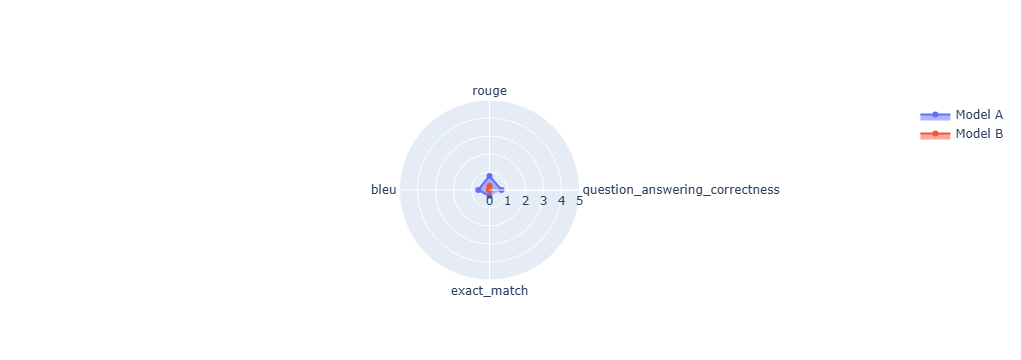

In [37]:
notebook_utils.display_radar_plot(
    referenced_eval_results,
    metrics=[
        "question_answering_correctness",
        "rouge",
        "bleu",
        "exact_match",
    ],
)

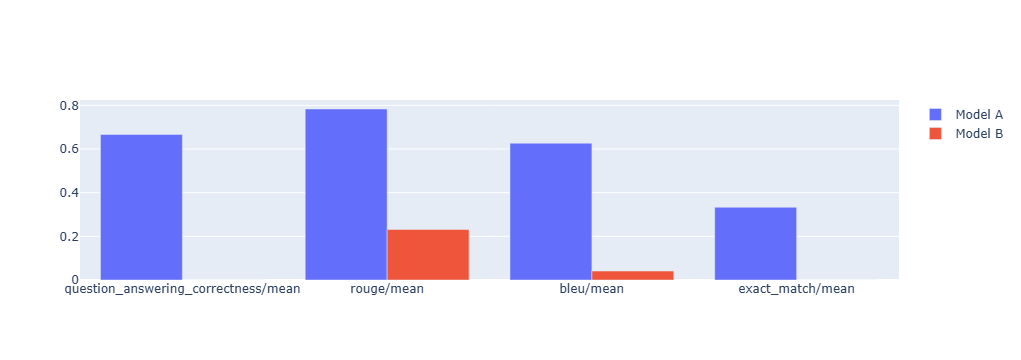

In [38]:
notebook_utils.display_bar_plot(
    referenced_eval_results,
    metrics=[
        "question_answering_correctness",
        "rouge",
        "bleu",
        "exact_match",
    ],
)

In [39]:
import pandas as pd

result_rag_a.metrics_table.to_csv(
    "model_a_details.csv", index=False
)

result_rag_b.metrics_table.to_csv(
    "model_b_details.csv", index=False
)

comparison = pd.DataFrame({
    "Model A": result_rag_a.summary_metrics,
    "Model B": result_rag_b.summary_metrics,
})

comparison.to_csv("evaluation_summary.csv")
print("Results saved.")

Results saved.
